# The burning calendar, Canada 2000–2025

Unit: a **cell-day**, one 0.01° grid cell on one date. `modis` counts cell-days MODIS detected;
`harmonized` adds the expected cell-days only VIIRS saw, using the multiplicity probabilities
from notebook 1. The comparison baseline is the 2012–2022 median.

In [1]:
from pathlib import Path

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)


In [2]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW = ROOT / "data" / "raw"
ARTIFACTS = ROOT / "web" / "public" / "artifacts"

GRID_DEG = 0.01
THREADS = 2  # this machine overheats at four

BINS = ["1", "2-3", "4-7", "8+"]
BIN_SQL = """case when n_viirs = 1 then 1
                  when n_viirs <= 3 then 2
                  when n_viirs <= 7 then 3
                  else 4 end"""

TOL_P = 1e-8        # model/CA.json stores probabilities to 8 dp
TOL_CORRECTION = 5e-3   # ... and corrections to 2 dp
TOL_CI = 1e-4       # ... and intervals to 4 dp
TOL_COUNT = 0.01    # calendar/CA.json stores counts to 2 dp
TOL_RATIO = 5e-4    # ... and ratios to 3 dp
TOL_LOSS = 5e-4     # ... and log-loss to 4 dp

con = duckdb.connect(config={"threads": THREADS})


def sql_paths(paths):
    return ", ".join(f"'{path.as_posix()}'" for path in paths)


def country_files(sensor, years, country):
    """Every expected CSV must exist; a missing year is an error, not an empty frame."""
    paths = [RAW / f"{sensor}_{year}_{country}.csv" for year in years]
    missing = [path.name for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(f"missing raw CSVs: {missing}")
    return paths


## Year × month cell-days

Same analysis frame as the published artifacts: `type = 0`, `frp > 0`, MODIS is Terra + Aqua,
VIIRS is Suomi NPP from 2012.

In [3]:
all_files = (
    country_files("modis", range(2000, 2026), "Canada")
    + country_files("viirs-snpp", range(2012, 2026), "Canada")
)
_ = con.sql(f"""
    create view raw as
    select case when filename ilike '%viirs%' then 'VIIRS' else 'MODIS' end as sensor,
           latitude, longitude, acq_date, satellite
    from read_csv([{sql_paths(all_files)}], union_by_name=true, filename=true)
    where type = 0 and frp > 0
""")

In [4]:
_ = con.sql(f"""
    create table cd as
    select sensor, satellite,
           round(latitude / {GRID_DEG})::bigint as clat,
           round(longitude / {GRID_DEG})::bigint as clon,
           acq_date, count(*) as n
    from raw
    group by 1, 2, 3, 4, 5
""")

In [5]:
_ = con.sql("""
    create table ev as
    select clat, clon, acq_date,
           cast(extract(year from acq_date) as int) as yr,
           cast(month(acq_date) as int) as mo,
           cast(dayofyear(acq_date) as int) as doy,
           coalesce(sum(n) filter (where sensor = 'MODIS'), 0) as n_modis,
           coalesce(sum(n) filter (where sensor = 'VIIRS'), 0) as n_viirs
    from cd
    group by 1, 2, 3
""")

## Calibrate the curve on 2012–2022

Identical to notebook 1, repeated so this notebook stands alone.

In [6]:
cal = con.sql(f"""
    select {BIN_SQL} as bin,
           count(*) as events,
           count(*) filter (where n_modis > 0) as hits
    from ev
    where n_viirs > 0 and yr between 2012 and 2022
    group by 1 order by 1
""").df()
cal["label"] = BINS
cal["p"] = cal.hits / cal.events
cal["correction"] = 1 / cal.p
cal.assign(
    p=cal.p.map(lambda value: f"{value:.8f}"),
    correction=cal.correction.map(lambda value: f"{value:.2f}"),
)[["label", "events", "p", "correction"]]

,label,events,p,correction
0,1,506113,0.13627984,7.34
1,2-3,374945,0.25587753,3.91
2,4-7,216320,0.43720414,2.29
3,8+,53041,0.64708433,1.55


In [7]:
p_by_bin = {int(row.bin): float(row.hits / row.events) for row in cal.itertuples()}
_ = con.sql("""
    create table pbin as
    select * from (values
        (1, ?), (2, ?), (3, ?), (4, ?)
    ) as t(bin, p)
""", params=[p_by_bin[i] for i in range(1, 5)])

_ = con.sql(f"""
    create table harm as
    select ev.*,
           case when n_modis > 0 then 1.0
                when n_viirs > 0 then pbin.p
                else 0.0 end as harmonized
    from ev
    left join pbin on pbin.bin = {BIN_SQL}
""")

In [8]:
monthly = con.sql("""
    select yr, mo,
           count(*) filter (where n_modis > 0) as modis,
           count(*) filter (where n_viirs > 0) as viirs,
           sum(harmonized) as harmonized
    from harm
    group by 1, 2 order by 1, 2
""").df()

annual = con.sql("""
    select yr,
           count(*) filter (where n_modis > 0) as modis,
           count(*) filter (where n_viirs > 0) as viirs,
           sum(harmonized) as harmonized
    from harm
    group by 1 order by 1
""").df()

## 2023 against the 2012–2022 median

Ratio is the 2023 annual count divided by the median annual count of the baseline years.

In [9]:
baseline = annual[annual.yr.between(2012, 2022)]
peak = annual[annual.yr == 2023].iloc[0]

peak_table = pd.DataFrame({
    "2023": [peak.modis, peak.harmonized],
    "2012-2022 median": [baseline.modis.median(), baseline.harmonized.median()],
}, index=["modis", "harmonized"])
peak_table["ratio"] = peak_table["2023"] / peak_table["2012-2022 median"]

assert round(peak_table.loc["modis", "ratio"], 3) == 5.124
assert round(peak_table.loc["harmonized", "ratio"], 3) == 5.176

pd.DataFrame({
    "measure": ["modis", "harmonized"],
    "2023": [f"{int(peak.modis):,}", f"{peak.harmonized:,.2f}"],
    "2012-2022 median": [
        f"{baseline.modis.median():,.0f}", f"{baseline.harmonized.median():,.2f}",
    ],
    "ratio": [
        f"{peak_table.loc['modis', 'ratio']:.3f}",
        f"{peak_table.loc['harmonized', 'ratio']:.3f}",
    ],
})

,measure,2023,2012-2022 median,ratio
0,modis,"253,699","49,511",5.124
1,harmonized,"355,541.97","68,690.29",5.176


## Why 2000–2002 ship but are not comparable

Raw MODIS detections (`type = 0`, `frp > 0`) by platform. The record opens in November 2000, 2001
is an archive gap, and Aqua joins in July 2002, so no standard score is computed for these years.

In [10]:
raw_counts = con.sql("""
    select year(acq_date) as yr, satellite, count(*) as detections
    from raw
    where year(acq_date) between 2000 and 2003
    group by 1, 2
""").df()

early = (
    raw_counts.pivot(index="yr", columns="satellite", values="detections")
    .fillna(0)
    .astype(int)
    .reindex(range(2000, 2004))
)[["Terra", "Aqua"]]
early

satellite,Terra,Aqua
yr,,
2000,830,0
2001,7673,0
2002,18824,9893
2003,25620,26225


In [11]:
aqua_2002 = con.sql("""
    select min(acq_date) as first_detection,
           count(*) filter (where month(acq_date) = 7) as july_detections
    from raw
    where satellite = 'Aqua' and year(acq_date) = 2002
""").df()

assert early.loc[2001, "Terra"] == 7673
assert early.loc[2003, "Terra"] == 25620
assert early.loc[2002, "Terra"] == 18824 and early.loc[2002, "Aqua"] == 9893
aqua_2002

,first_detection,july_detections
0,2002-07-04,6909


## The 2023 season against the 2012–2022 band

Harmonized cell-days per day. The artifact stores 366 slots per year indexed `day-of-year − 1`,
so a leap year places 29 February where other years place 1 March; the band uses that convention.

In [12]:
daily = con.sql("""
    select yr, doy, sum(harmonized) as harmonized
    from harm
    group by 1, 2
""").df()

days = np.arange(1, 367)
daily_grid = daily.pivot(index="yr", columns="doy", values="harmonized").reindex(columns=days).fillna(0.0)
band = daily_grid.loc[2012:2022].to_numpy()
season_2023 = daily_grid.loc[2023].to_numpy()

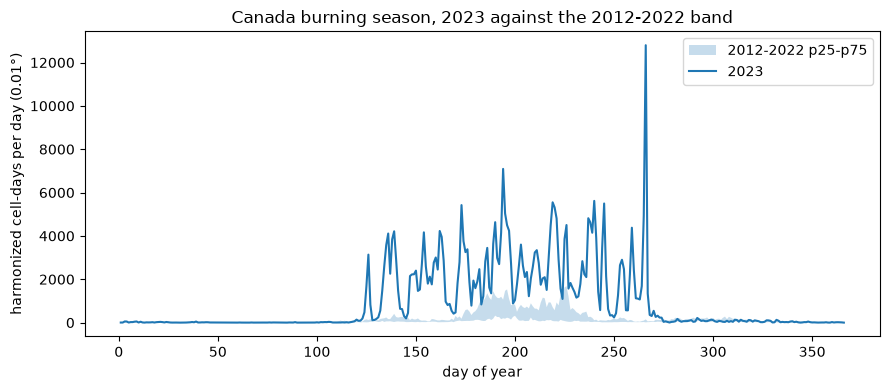

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(days, np.percentile(band, 25, axis=0), np.percentile(band, 75, axis=0),
                alpha=0.25, label="2012-2022 p25-p75")
ax.plot(days, season_2023, label="2023")
ax.set(
    xlabel="day of year",
    ylabel="harmonized cell-days per day (0.01°)",
    title="Canada burning season, 2023 against the 2012-2022 band",
)
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'season-2023.png', dpi=150)

## Assertions against `calendar/CA.json` and `model/CA.json`

Tolerances: probabilities 1e-8, counts 0.01, ratios 5e-4.

In [14]:
published_calendar = json.loads((ARTIFACTS / "calendar/CA.json").read_text())
published_model = json.loads((ARTIFACTS / "model/CA.json").read_text())

cells_doc = {(entry["y"], entry["m"]): entry for entry in published_calendar["cells"]}
assert len(cells_doc) == len(monthly)
for _, row in monthly.iterrows():
    doc = cells_doc[(row.yr, row.mo)]
    assert int(row.modis) == doc["modis"]
    if row.yr >= 2012:
        assert abs(row.harmonized - doc["harmonized"]) < TOL_COUNT
    else:
        assert doc["harmonized"] is None

annual_doc = {entry["year"]: entry for entry in published_calendar["annual"]}
for _, row in annual.iterrows():
    doc = annual_doc[int(row.yr)]
    assert int(row.modis) == doc["modis"]
    if row.yr >= 2012:
        assert abs(row.harmonized - doc["harmonized"]) < TOL_COUNT
        assert abs(row.harmonized / doc["harmonized"] - 1) < 1e-6
    else:
        assert doc["harmonized"] is None

for year in published_calendar["non_comparable_years"]:
    assert annual_doc[year]["ratio"]["modis"] is None
    assert annual_doc[year]["z"]["modis"] is None

published_series = np.array(published_calendar["series"][2023 - 2000]["harmonized"])
assert np.max(np.abs(season_2023 - published_series)) < TOL_COUNT

bins_doc = {entry["label"]: entry for entry in published_model["multiplicity_bins"]}
for _, row in cal.iterrows():
    assert abs(row.p - bins_doc[row.label]["p"]) < TOL_P
    assert abs(row.correction - bins_doc[row.label]["correction"]) < TOL_CORRECTION

assert abs(peak_table.loc["modis", "ratio"] - annual_doc[2023]["ratio"]["modis"]) < TOL_RATIO
assert abs(peak_table.loc["harmonized", "ratio"] - annual_doc[2023]["ratio"]["harmonized"]) < TOL_RATIO
assert abs(peak_table.loc["modis", "ratio"] - published_calendar["peak"]["ratio"]) < TOL_RATIO

print(f"notebook 2: {len(monthly)} months, {len(annual)} years and the 2023 daily series "
      f"match calendar/CA.json")

notebook 2: 302 months, 26 years and the 2023 daily series match calendar/CA.json
